<a href="https://colab.research.google.com/github/emazarchie-cpu/emazarchie.github.io/blob/main/RoboFitness_Client_Management_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoboFitness Client Retention and Revenue Analytics

### Project Overview

This project explores how Python can be used to solve a real world business problem involving client retention, personal training revenue, and income growth.

While working at RoboFitness PT, I identified a challenge: client cancellations can reduce monthly commission, making it difficult to maintain a consistent income and achieve financial targets.

My objective was to build a Python based analytics tool that calculates monthly earnings, tracks active clients, estimates the financial impact of cancellations, and determines the number of paying clients required to reach a defined income goal.

Using Python, Pandas, and Matplotlib in Google Colab, I developed a system for organizing client information, calculating commission, forecasting potential client losses, and comparing different revenue scenarios.

This project represents my approach to problem solving: identifying a practical challenge, translating it into measurable variables, implementing a solution, and interpreting the results to support better business decisions.

**Key concepts:** Python programming, data analysis, revenue forecasting, customer retention, business intelligence, and data driven decision making.

       ROBOFITNESS BUSINESS MANAGEMENT SYSTEM

Base salary: ₦100,000
Training fee per client: ₦77,000
Your commission rate: 35%
Your commission per client: ₦26,950
Monthly income target: ₦400,000
Minimum paying clients required: 12


CURRENT CLIENT DATABASE
------------------------------------------------------------
      Client   Status  Month Renewal_Risk
     Ibrahim   Active      2       Medium
        Noah InActive      1          Low
        Lucy   Active      2       Medium
      Isabel   Active      2       Medium
    Mohammed   Active      1          Low
Mr. Adesanya   Active      1          Low
        Alex InActive      1          Low
Ms. Adesanya   Active      1          Low


CURRENT REVENUE REPORT
------------------------------------------------------------
Active clients: 6
Base salary: ₦100,000
Commission: ₦161,700
Total income: ₦261,700
Amount below target: ₦138,300


CLIENT RETENTION ANALYSIS
------------------------------------------------------------
Starting clien

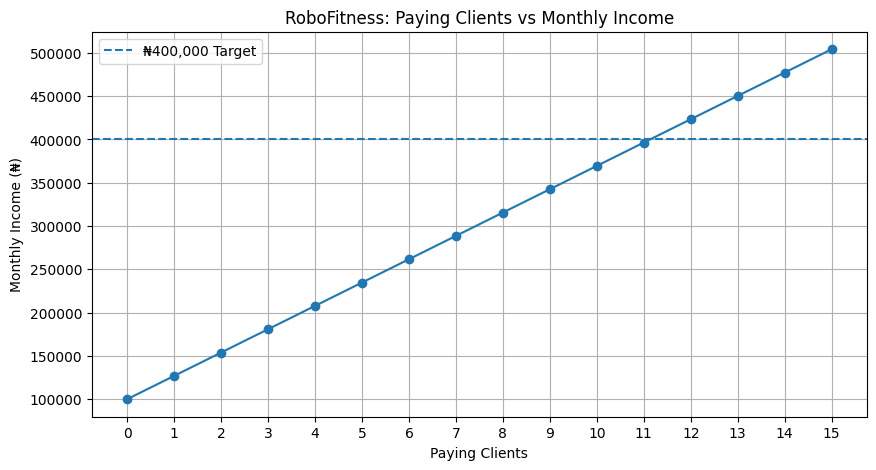



FINAL RECOMMENDATION
Your minimum target is 12 paying clients.
At this client count, your expected monthly income is ₦423,400.
Track attendance, renewal intentions, and client satisfaction every week.
Build a pipeline of prospects before cancellations occur, and replace lost clients promptly.
Update the client database with real information before using it to make business decisions.


In [4]:
# ============================================================
# ROBOFITNESS CLIENT RETENTION & REVENUE MANAGEMENT SYSTEM
# Author: Emmanuel Archibong
# Purpose: Manage clients, forecast cancellations, and target
#          a monthly income of at least ₦400,000.
# ============================================================

import pandas as pd
import math

# ------------------------------------------------------------
# 1. BUSINESS SETTINGS
# ------------------------------------------------------------

BASE_SALARY = 100_000
TRAINING_FEE = 77_000
COMMISSION_RATE = 0.35
COMMISSION_PER_CLIENT = TRAINING_FEE * COMMISSION_RATE

TARGET_INCOME = 400_000
EXPECTED_CANCELLATION_RATE = 0.25

CURRENT_CLIENTS = 8
FORECAST_MONTHS = 3

# Minimum clients needed to reach the income target
MIN_CLIENTS_FOR_TARGET = math.ceil(
    (TARGET_INCOME - BASE_SALARY) / COMMISSION_PER_CLIENT
)

print("=" * 60)
print("       ROBOFITNESS BUSINESS MANAGEMENT SYSTEM")
print("=" * 60)

print(f"\nBase salary: ₦{BASE_SALARY:,.0f}")
print(f"Training fee per client: ₦{TRAINING_FEE:,.0f}")
print(f"Your commission rate: {COMMISSION_RATE:.0%}")
print(f"Your commission per client: ₦{COMMISSION_PER_CLIENT:,.0f}")
print(f"Monthly income target: ₦{TARGET_INCOME:,.0f}")
print(f"Minimum paying clients required: {MIN_CLIENTS_FOR_TARGET}")


# ------------------------------------------------------------
# 2. CREATE YOUR CLIENT DATABASE
# ------------------------------------------------------------

# Replace these sample names and statuses with your actual
# client information before relying on the report.

clients = pd.DataFrame({
    "Client": [
        "Ibrahim", "Noah", "Lucy", "Isabel",
        "Mohammed", "Mr. Adesanya", "Alex", "Ms. Adesanya"
    ],
    "Status": [
        "Active", "InActive", "Active", "Active",
        "Active", "Active", "InActive", "Active"
    ],
    "Month": [
        2, 1, 2, 2, 1, 1, 1, 1
    ],
    "Renewal_Risk": [
        "Medium", "Low", "Medium", "Medium",
        "Low", "Low", "Low", "Low"
    ]
})

print("\n\nCURRENT CLIENT DATABASE")
print("-" * 60)
print(clients.to_string(index=False))


# ------------------------------------------------------------
# 3. CALCULATE CURRENT REVENUE
# ------------------------------------------------------------

def calculate_income(number_of_clients):
    commission = number_of_clients * COMMISSION_PER_CLIENT
    total_income = BASE_SALARY + commission

    return {
        "clients": number_of_clients,
        "base_salary": BASE_SALARY,
        "commission": commission,
        "total_income": total_income,
        "target_gap": max(0, TARGET_INCOME - total_income)
    }


active_clients = (clients["Status"] == "Active").sum()
current = calculate_income(active_clients)

print("\n\nCURRENT REVENUE REPORT")
print("-" * 60)
print(f"Active clients: {current['clients']}")
print(f"Base salary: ₦{current['base_salary']:,.0f}")
print(f"Commission: ₦{current['commission']:,.0f}")
print(f"Total income: ₦{current['total_income']:,.0f}")
print(f"Amount below target: ₦{current['target_gap']:,.0f}")


# ------------------------------------------------------------
# 4. CALCULATE CLIENT REPLACEMENT NEEDS
# ------------------------------------------------------------

expected_cancellations = (
    CURRENT_CLIENTS * EXPECTED_CANCELLATION_RATE
)

expected_retained = (
    CURRENT_CLIENTS - expected_cancellations
)

replacement_to_preserve_eight = max(
    0, math.ceil(CURRENT_CLIENTS - expected_retained)
)

new_clients_for_income_target = max(
    0, MIN_CLIENTS_FOR_TARGET - CURRENT_CLIENTS
)

print("\n\nCLIENT RETENTION ANALYSIS")
print("-" * 60)
print(f"Starting clients: {CURRENT_CLIENTS}")
print(
    "Expected cancellations: "
    f"{expected_cancellations:.1f}"
)
print(f"Expected retained clients: {expected_retained:.1f}")
print(
    "Replacement clients needed to preserve eight: "
    f"{replacement_to_preserve_eight}"
)
print(
    "Additional clients needed to grow from eight "
    f"to {MIN_CLIENTS_FOR_TARGET}: "
    f"{new_clients_for_income_target}"
)


# ------------------------------------------------------------
# 5. THREE-MONTH REVENUE FORECAST
# ------------------------------------------------------------

# This forecast assumes the cancellation rate applies to
# clients active at the beginning of each month.
#
# New clients are acquired at the beginning of each month.
# The model uses EXPECTED client counts, so decimal counts
# represent statistical averages, not actual people.

forecast = []
expected_active = float(CURRENT_CLIENTS)

for month in range(1, FORECAST_MONTHS + 1):

    expected_lost = (
        expected_active * EXPECTED_CANCELLATION_RATE
    )

    expected_active = expected_active - expected_lost

    forecast_income = (
        BASE_SALARY +
        expected_active * COMMISSION_PER_CLIENT
    )

    forecast.append({
        "Month": month,
        "Expected_Active_Clients": round(expected_active, 2),
        "Expected_Cancellations": round(expected_lost, 2),
        "Expected_Income": round(forecast_income, 2),
        "Income_Gap": round(
            max(0, TARGET_INCOME - forecast_income), 2
        )
    })

forecast_df = pd.DataFrame(forecast)

print("\n\nTHREE-MONTH FORECAST WITHOUT REPLACEMENTS")
print("-" * 60)
print(forecast_df.to_string(index=False))


# ------------------------------------------------------------
# 6. CLIENT ACQUISITION TARGET
# ------------------------------------------------------------

# We want to maintain the required client count even when
# cancellations occur.

TARGET_CLIENTS = MIN_CLIENTS_FOR_TARGET

def acquisition_plan(active_count, target_count, cancellation_rate):
    expected_losses = active_count * cancellation_rate

    growth_needed = max(0, target_count - active_count)

    # Round expected losses upward for a conservative target.
    replacement_buffer = math.ceil(expected_losses)

    total_new_clients_needed = growth_needed + replacement_buffer

    return {
        "current_clients": active_count,
        "target_clients": target_count,
        "expected_losses": round(expected_losses, 2),
        "growth_needed": growth_needed,
        "replacement_buffer": replacement_buffer,
        "total_new_clients_needed": total_new_clients_needed
    }


plan = acquisition_plan(
    CURRENT_CLIENTS,
    TARGET_CLIENTS,
    EXPECTED_CANCELLATION_RATE
)

print("\n\nCLIENT ACQUISITION PLAN")
print("-" * 60)
print(f"Current clients: {plan['current_clients']}")
print(f"Income-target client count: {plan['target_clients']}")
print(f"Expected cancellations: {plan['expected_losses']}")
print(f"Growth clients required: {plan['growth_needed']}")
print(f"Replacement buffer: {plan['replacement_buffer']}")
print(
    "Total new clients to target: "
    f"{plan['total_new_clients_needed']}"
)


# ------------------------------------------------------------
# 7. CLIENT RETENTION ACTION LIST
# ------------------------------------------------------------

def retention_action(row):
    if row["Status"] != "Active":
        return "Contact and assess reactivation potential"

    if row["Renewal_Risk"] == "High":
        return "Priority: speak with client and agree on next steps"

    if row["Renewal_Risk"] == "Medium":
        return "Check progress, attendance, and renewal intentions"

    return "Maintain progress reviews and engagement"


clients["Recommended_Action"] = clients.apply(
    retention_action, axis=1
)

print("\n\nCLIENT RETENTION ACTION LIST")
print("-" * 60)
print(
    clients[
        ["Client", "Status", "Month", "Renewal_Risk",
         "Recommended_Action"]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 8. INCOME SCENARIO COMPARISON
# ------------------------------------------------------------

scenario_rows = []

for number in range(0, 16):
    result = calculate_income(number)

    scenario_rows.append({
        "Paying_Clients": number,
        "Commission": result["commission"],
        "Total_Income": result["total_income"],
        "Target_Reached": (
            result["total_income"] >= TARGET_INCOME
        )
    })

scenario_df = pd.DataFrame(scenario_rows)

print("\n\nINCOME SCENARIOS")
print("-" * 60)
print(scenario_df.to_string(index=False))


# ------------------------------------------------------------
# 9. VISUALIZE CLIENT COUNT AND INCOME
# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    scenario_df["Paying_Clients"],
    scenario_df["Total_Income"],
    marker="o"
)

plt.axhline(
    y=TARGET_INCOME,
    linestyle="--",
    label="₦400,000 Target"
)

plt.xlabel("Paying Clients")
plt.ylabel("Monthly Income (₦)")
plt.title("RoboFitness: Paying Clients vs Monthly Income")
plt.xticks(range(0, 16))
plt.grid(True)
plt.legend()
plt.show()


# ------------------------------------------------------------
# 10. FINAL BUSINESS RECOMMENDATION
# ------------------------------------------------------------

print("\n\nFINAL RECOMMENDATION")
print("=" * 60)

print(
    f"Your minimum target is {MIN_CLIENTS_FOR_TARGET} "
    "paying clients."
)

print(
    "At this client count, your expected monthly income is "
    f"₦{calculate_income(MIN_CLIENTS_FOR_TARGET)['total_income']:,.0f}."
)

print(
    "Track attendance, renewal intentions, and client "
    "satisfaction every week."
)

print(
    "Build a pipeline of prospects before cancellations "
    "occur, and replace lost clients promptly."
)

print(
    "Update the client database with real information "
    "before using it to make business decisions."
)

# RoboFitness growth planner

ROBOFITNESS REVENUE GROWTH & CLIENT ACQUISITION PLANNER

Base salary: NGN 100,000
Commission per client: NGN 26,950
Original cancellation rate: 25%
Effective cancellation rate: 20%

MONTHLY INCOME AND CLIENT TARGETS
---------------------------------------------------------------------------
        Month Income_Target  Clients_Required Calculated_Income Income_Above_Target
 October 2026   NGN 400,000                12       NGN 423,400          NGN 23,400
November 2026   NGN 560,000                18       NGN 585,100          NGN 25,100
December 2026   NGN 720,000                24       NGN 746,800          NGN 26,800
 January 2027   NGN 880,000                29       NGN 881,550           NGN 1,550
February 2027 NGN 1,040,000                35     NGN 1,043,250           NGN 3,250
   March 2027 NGN 1,200,000                41     NGN 1,204,950           NGN 4,950


MONTHLY CLIENT RETENTION & ACQUISITION PLAN
--------------------------------------------------------------------------

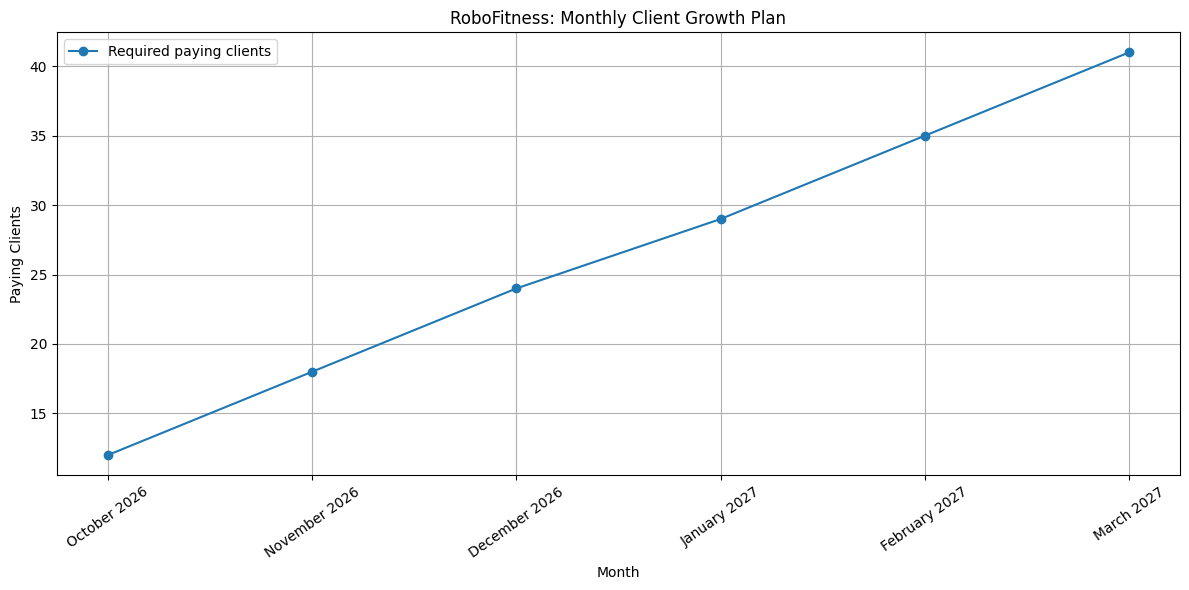

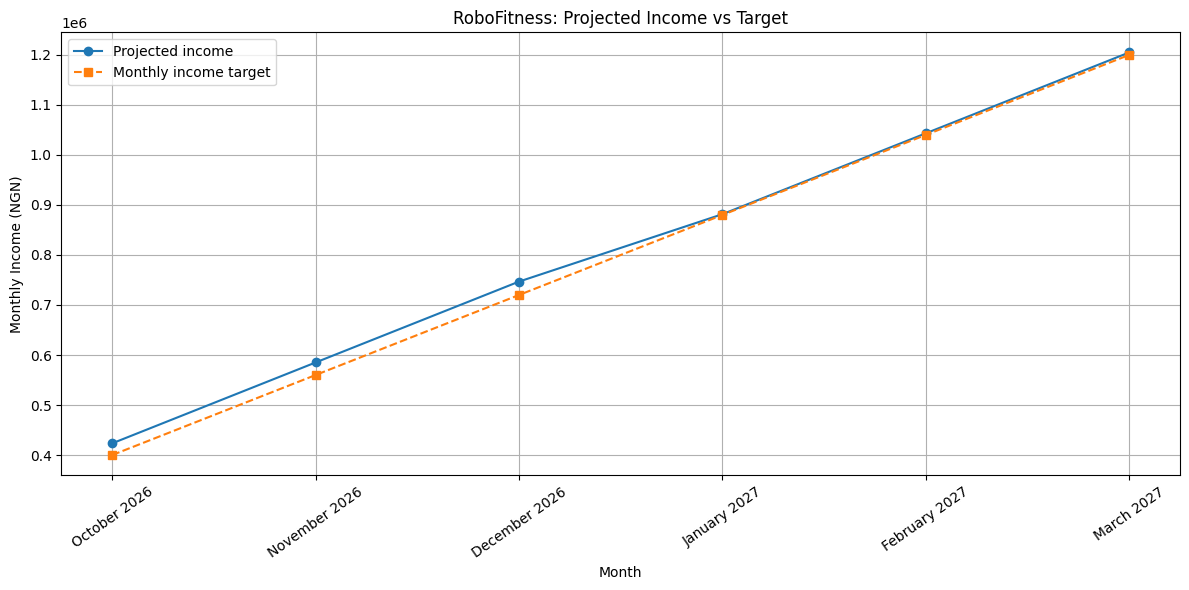



FINAL GROWTH SUMMARY
October starting client base: 12
March paying-client target: 41
March projected monthly income: NGN 1,204,950
March income target: NGN 1,200,000
Monthly income above target: NGN 4,950

BUSINESS ACTION PLAN:
1. Review client attendance and progress every week.
2. Begin renewal conversations before each plan expires.
3. Follow up with inactive clients and record their reasons for stopping.
4. Maintain a prospect pipeline for replacement clients.
5. Acquire additional clients to meet the next month's paying-client target.
6. Compare actual cancellations and acquisitions against these projections every month.

This model is a scenario-planning tool. Its results depend on the assumed cancellation rate and acquisition plan.


In [6]:
# ============================================================
# ROBOFITNESS REVENUE GROWTH & CLIENT ACQUISITION PLANNER
#
# Objective:
# Plan monthly income growth from October 2026 to March 2027.
#
# Compensation:
# Base salary = NGN 100,000
# Training plan = NGN 77,000
# Commission = 35% of each plan
#
# Model includes:
# 1. Monthly income targets
# 2. Client cancellations
# 3. Retention intervention scenarios
# 4. Replacement clients
# 5. Additional client acquisition
# 6. Monthly revenue forecasting
# 7. Growth visualization
#
# Note:
# This is a planning model, not a validated ML predictor.
# ============================================================

import math
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. BUSINESS SETTINGS
# ------------------------------------------------------------

BASE_SALARY = 100_000
TRAINING_FEE = 77_000
COMMISSION_RATE = 0.35

COMMISSION_PER_CLIENT = TRAINING_FEE * COMMISSION_RATE

INITIAL_CLIENTS = 12

STARTING_MONTHLY_TARGET = 400_000
FINAL_MONTHLY_TARGET = 1_200_000

CANCELLATION_RATE = 0.25

# Illustrative assumption:
# Retention actions reduce the cancellation rate by 20%
# relative to the original rate.
#
# 25% * (1 - 20%) = 20%
RETENTION_EFFECTIVENESS = 0.20

IMPROVED_CANCELLATION_RATE = (
    CANCELLATION_RATE * (1 - RETENTION_EFFECTIVENESS)
)

MONTHS = [
    "October 2026",
    "November 2026",
    "December 2026",
    "January 2027",
    "February 2027",
    "March 2027"
]

# Set True to simulate improved retention.
# Set False to use the original 25% cancellation rate.
USE_RETENTION_INTERVENTION = True

ACTIVE_CANCELLATION_RATE = (
    IMPROVED_CANCELLATION_RATE
    if USE_RETENTION_INTERVENTION
    else CANCELLATION_RATE
)

# ------------------------------------------------------------
# 2. DEFINE MONTHLY INCOME TARGETS
# ------------------------------------------------------------

monthly_targets = [
    400_000,
    560_000,
    720_000,
    880_000,
    1_040_000,
    1_200_000
]

def clients_required(income_target):
    """
    Calculate the minimum whole number of paying clients
    required to meet or exceed an income target.
    """
    return math.ceil(
        max(0, income_target - BASE_SALARY)
        / COMMISSION_PER_CLIENT
    )


def calculate_income(number_of_clients):
    """
    Calculate monthly income from the base salary
    and commission generated by paying clients.
    """
    commission = number_of_clients * COMMISSION_PER_CLIENT

    return BASE_SALARY + commission


# ------------------------------------------------------------
# 3. DISPLAY THE CLIENT TARGETS
# ------------------------------------------------------------

print("=" * 75)
print("ROBOFITNESS REVENUE GROWTH & CLIENT ACQUISITION PLANNER")
print("=" * 75)

print(f"\nBase salary: NGN {BASE_SALARY:,.0f}")
print(f"Commission per client: NGN {COMMISSION_PER_CLIENT:,.0f}")
print(f"Original cancellation rate: {CANCELLATION_RATE:.0%}")
print(f"Effective cancellation rate: {ACTIVE_CANCELLATION_RATE:.0%}")

target_rows = []

for month, target in zip(MONTHS, monthly_targets):

    required = clients_required(target)
    income = calculate_income(required)

    target_rows.append({
        "Month": month,
        "Income_Target": target,
        "Clients_Required": required,
        "Calculated_Income": income,
        "Income_Above_Target": income - target
    })

target_df = pd.DataFrame(target_rows)

print("\nMONTHLY INCOME AND CLIENT TARGETS")
print("-" * 75)

print(
    target_df.to_string(
        index=False,
        formatters={
            "Income_Target": lambda x: f"NGN {x:,.0f}",
            "Calculated_Income": lambda x: f"NGN {x:,.0f}",
            "Income_Above_Target": lambda x: f"NGN {x:,.0f}"
        }
    )
)


# ------------------------------------------------------------
# 4. MODEL CLIENT CANCELLATIONS AND ACQUISITION
# ------------------------------------------------------------

# Planning convention:
# - Start October with 12 paying clients.
# - At the beginning of each subsequent month, apply the
#   assumed cancellation rate to the previous month's
#   paying-client count.
# - Round expected cancellations up to whole clients.
# - Acquire enough paying clients to reach that month's
#   target.
#
# This conservative whole-client model avoids relying on
# fractional clients. It assumes new clients acquired for a
# month can generate commission during that month.
#
# Actual acquisition timing and commission eligibility
# should be adjusted to match RoboFitness payroll rules.

forecast_rows = []

previous_month_end_clients = INITIAL_CLIENTS

for index, month in enumerate(MONTHS):

    target_income = monthly_targets[index]

    target_clients = clients_required(target_income)

    if index == 0:
        # October starts with the planned 12 paying clients.
        starting_clients = INITIAL_CLIENTS
        cancellations = 0
        retained_clients = INITIAL_CLIENTS

    else:
        starting_clients = previous_month_end_clients

        expected_cancellations = (
            starting_clients * ACTIVE_CANCELLATION_RATE
        )

        # Round upward to avoid understating potential losses.
        cancellations = min(
            starting_clients,
            math.ceil(expected_cancellations)
        )

        retained_clients = starting_clients - cancellations

    # Calculate the minimum new paying clients needed to
    # reach the current month's income target.
    new_clients_needed = max(
        0,
        target_clients - retained_clients
    )

    ending_clients = retained_clients + new_clients_needed

    actual_income = calculate_income(ending_clients)

    # All newly acquired clients in this simplified model
    # are assumed to be paying and commission-eligible.
    #
    # Replacement clients = clients lost to cancellation,
    # capped at the total acquisition requirement.
    replacement_clients = min(
        cancellations,
        new_clients_needed
    )

    growth_clients = max(
        0,
        new_clients_needed - replacement_clients
    )

    forecast_rows.append({
        "Month": month,
        "Starting_Clients": starting_clients,
        "Cancellations": cancellations,
        "Retained_Clients": retained_clients,
        "Replacement_Clients": replacement_clients,
        "Growth_Clients": growth_clients,
        "New_Clients_Needed": new_clients_needed,
        "Ending_Clients": ending_clients,
        "Income_Target": target_income,
        "Projected_Income": actual_income
    })

    previous_month_end_clients = ending_clients

forecast_df = pd.DataFrame(forecast_rows)

# ------------------------------------------------------------
# 5. DISPLAY THE GROWTH PLAN
# ------------------------------------------------------------

print("\n\nMONTHLY CLIENT RETENTION & ACQUISITION PLAN")
print("-" * 100)

print(
    forecast_df.to_string(
        index=False,
        formatters={
            "Income_Target": lambda x: f"NGN {x:,.0f}",
            "Projected_Income": lambda x: f"NGN {x:,.0f}"
        }
    )
)

# ------------------------------------------------------------
# 6. CALCULATE TOTAL ACQUISITION REQUIREMENTS
# ------------------------------------------------------------

total_replacements = forecast_df["Replacement_Clients"].sum()

total_growth_clients = forecast_df["Growth_Clients"].sum()

total_new_clients = forecast_df["New_Clients_Needed"].sum()

print("\n\nTOTAL CLIENT ACQUISITION REQUIREMENTS")
print("-" * 75)

print(f"Initial October clients: {INITIAL_CLIENTS}")
print(f"Total replacement clients planned: {total_replacements}")
print(f"Total growth clients planned: {total_growth_clients}")
print(f"Total new clients required across the period: {total_new_clients}")

print(
    "\nImportant: These are acquisition events, not necessarily "
    "unique individuals. A replacement client is counted when "
    "acquired to offset a cancellation."
)

# ------------------------------------------------------------
# 7. COMPARE RETENTION SCENARIOS
# ------------------------------------------------------------

def simulate_scenario(cancellation_rate, scenario_name):

    previous_clients = INITIAL_CLIENTS
    rows = []

    for index, month in enumerate(MONTHS):

        target_income = monthly_targets[index]
        target_clients = clients_required(target_income)

        if index == 0:
            cancellations = 0
            retained = INITIAL_CLIENTS
        else:
            cancellations = min(
                previous_clients,
                math.ceil(previous_clients * cancellation_rate)
            )

            retained = previous_clients - cancellations

        new_clients = max(0, target_clients - retained)
        ending_clients = retained + new_clients

        rows.append({
            "Scenario": scenario_name,
            "Month": month,
            "Cancellation_Rate": cancellation_rate,
            "Cancellations": cancellations,
            "New_Clients": new_clients,
            "Ending_Clients": ending_clients,
            "Projected_Income": calculate_income(ending_clients)
        })

        previous_clients = ending_clients

    return pd.DataFrame(rows)


baseline_df = simulate_scenario(
    CANCELLATION_RATE,
    "Original 25% cancellation"
)

retention_df = simulate_scenario(
    IMPROVED_CANCELLATION_RATE,
    "Improved retention scenario"
)

comparison_df = pd.concat(
    [baseline_df, retention_df],
    ignore_index=True
)

print("\n\nCANCELLATION SCENARIO COMPARISON")
print("-" * 85)

print(
    comparison_df[
        [
            "Scenario",
            "Month",
            "Cancellations",
            "New_Clients",
            "Ending_Clients",
            "Projected_Income"
        ]
    ].to_string(
        index=False,
        formatters={
            "Projected_Income": lambda x: f"NGN {x:,.0f}"
        }
    )
)

# ------------------------------------------------------------
# 8. VISUALIZE CLIENT GROWTH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_df["Month"],
    forecast_df["Ending_Clients"],
    marker="o",
    label="Required paying clients"
)

plt.title("RoboFitness: Monthly Client Growth Plan")
plt.xlabel("Month")
plt.ylabel("Paying Clients")
plt.xticks(rotation=35)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VISUALIZE PROJECTED INCOME
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_df["Month"],
    forecast_df["Projected_Income"],
    marker="o",
    label="Projected income"
)

plt.plot(
    forecast_df["Month"],
    forecast_df["Income_Target"],
    marker="s",
    linestyle="--",
    label="Monthly income target"
)

plt.title("RoboFitness: Projected Income vs Target")
plt.xlabel("Month")
plt.ylabel("Monthly Income (NGN)")
plt.xticks(rotation=35)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

march = forecast_df.iloc[-1]

print("\n\nFINAL GROWTH SUMMARY")
print("=" * 75)

print(
    f"October starting client base: {INITIAL_CLIENTS}"
)

print(
    f"March paying-client target: {int(march['Ending_Clients'])}"
)

print(
    f"March projected monthly income: "
    f"NGN {march['Projected_Income']:,.0f}"
)

print(
    f"March income target: NGN {FINAL_MONTHLY_TARGET:,.0f}"
)

print(
    f"Monthly income above target: "
    f"NGN {march['Projected_Income'] - FINAL_MONTHLY_TARGET:,.0f}"
)

print(
    "\nBUSINESS ACTION PLAN:"
)

print(
    "1. Review client attendance and progress every week."
)

print(
    "2. Begin renewal conversations before each plan expires."
)

print(
    "3. Follow up with inactive clients and record their reasons "
    "for stopping."
)

print(
    "4. Maintain a prospect pipeline for replacement clients."
)

print(
    "5. Acquire additional clients to meet the next month's "
    "paying-client target."
)

print(
    "6. Compare actual cancellations and acquisitions against "
    "these projections every month."
)

print(
    "\nThis model is a scenario-planning tool. Its results depend "
    "on the assumed cancellation rate and acquisition plan."
)

       ROBOFITNESS CLIENT & REVENUE MANAGEMENT SYSTEM

Base salary: ₦100,000
Commission per paying client: ₦26,950
Current clients: 8
Current estimated cancellation rate: 25%

--- CURRENT REVENUE ---
Clients: 8
Commission: ₦215,600
Total income: ₦315,600
Gap to ₦400,000: ₦84,400
Clients needed for ₦400,000: 12
Clients needed for ₦1,200,000: 41

--- CLIENT DATABASE ---


,Client,Status,Sessions_Per_Week,Days,Preferred_Start,Monthly_Plan_Paid
0,Ibrahim,Active,3,"Tue, Thu, Sat",15:00,True
1,Lucy,Active,3,"Tue, Thu, Fri",07:00,True
2,Isabel,Active,3,"Tue, Thu, Fri",13:00,True
3,Mohammed,Active,3,"Tue, Wed, Thu",11:00,True
4,Albert,Active,3,"Tue, Thu, Sat",18:00,True
5,Albert's Wife,Active,3,"Tue, Thu, Sat",18:00,True
6,Noah,Paused,3,"Mon, Wed, Fri",09:00,False
7,Alex,Paused,3,"Mon, Wed, Sat",10:00,False
8,Rita,Potential,3,"Mon, Tue, Thu",08:00,False



--- WEEKLY TIMETABLE ---


,Day,Start,End,Client,Status
0,Monday,08:00,09:00,Rita,Potential
1,Monday,09:00,10:00,Noah,Paused
2,Monday,10:00,11:00,Alex,Paused
3,Monday,18:00,19:00,New client slot 1,Available
4,Monday,19:00,20:00,New client slot 2,Available
5,Tuesday,07:00,08:00,Lucy,Active
6,Tuesday,08:00,09:00,Rita,Potential
7,Tuesday,11:00,12:00,Mohammed,Active
8,Tuesday,13:00,14:00,Isabel,Active
9,Tuesday,15:00,16:00,Ibrahim,Active



--- DOUBLE-BOOKING CHECK ---
No overlapping appointments detected.

--- CLIENT REPLACEMENT PLAN ---


,Starting Clients,Expected Cancellations,Retained Clients,Target Clients,Replacement Clients,Growth Clients,Total New Clients Needed
0,8,2,6,12,2,6,8



--- REVENUE GROWTH ROADMAP ---


,Month,Income Target,Clients Required,Increase vs Previous Target,Commission,Projected Income
0,October 2026,400000,12,12,323400.0,423400.0
1,November 2026,560000,18,6,485100.0,585100.0
2,December 2026,720000,24,6,646800.0,746800.0
3,January 2027,880000,29,5,781550.0,881550.0
4,February 2027,1040000,35,6,943250.0,1043250.0
5,March 2027,1200000,41,6,1104950.0,1204950.0



--- WEEKLY CAPACITY ESTIMATE ---
Theoretical weekly hours: 75.0
After reserving 1 hour/day for breaks/admin: 69.0
Approximate one-to-one client capacity at 3 sessions/week: 23 clients
Approximate one-to-one client capacity at 2 sessions/week: 34 clients

Important: these are upper-bound estimates. Your actual capacity depends on appointment lengths, travel, breaks, shared sessions and client availability.


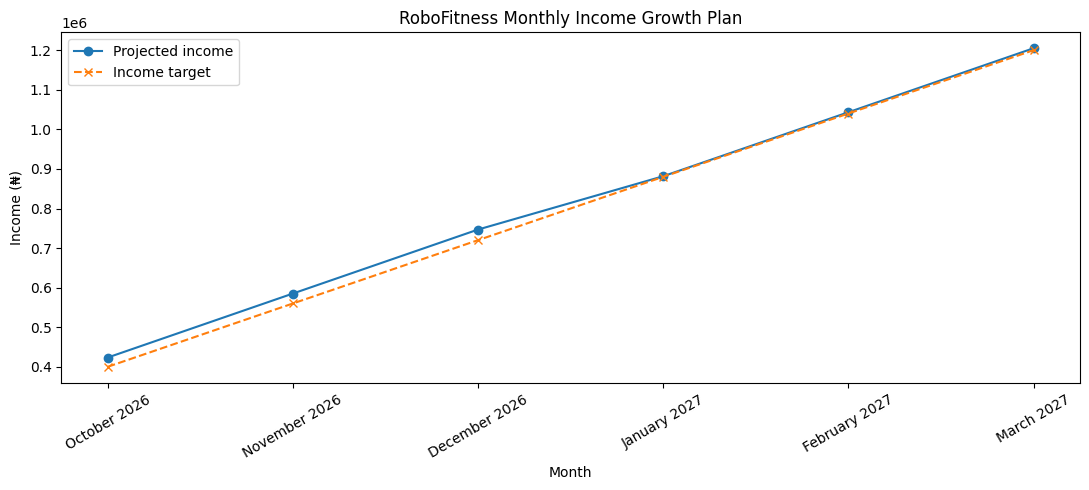


--- WEEKLY BUSINESS ACTIONS ---


,Priority,Action,Purpose
0,1,Contact paused clients,Confirm whether they will resume or cancel
1,2,Convert potential clients,Follow up with Rita and other leads
2,3,Track payments monthly,Only count commission-eligible paying clients
3,4,Check attendance weekly,Identify missed sessions before clients disengage
4,5,Ask satisfied clients for referrals,Create a consistent source of new leads
5,6,Protect 4 PM–6 PM,Maintain football development and athletic per...
6,7,Review timetable conflicts,Avoid double-bookings and unrealistic appointm...



REPORT COMPLETE


In [7]:
# ============================================================
# ROBOFITNESS CLIENT & REVENUE MANAGEMENT SYSTEM
# Google Colab compatible
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from math import ceil

# ------------------------------------------------------------
# 1. BUSINESS SETTINGS
# ------------------------------------------------------------

BASE_SALARY = 100_000
PLAN_PRICE = 77_000
COMMISSION_RATE = 0.35
COMMISSION_PER_CLIENT = PLAN_PRICE * COMMISSION_RATE

CURRENT_CLIENTS = 8
CANCELLATION_RATE = 0.25

CURRENT_MONTHLY_TARGET = 400_000
MARCH_2027_TARGET = 1_200_000

FOOTBALL_START = "16:00"
FOOTBALL_END = "18:00"

print("=" * 65)
print("       ROBOFITNESS CLIENT & REVENUE MANAGEMENT SYSTEM")
print("=" * 65)

print(f"\nBase salary: ₦{BASE_SALARY:,.0f}")
print(f"Commission per paying client: ₦{COMMISSION_PER_CLIENT:,.0f}")
print(f"Current clients: {CURRENT_CLIENTS}")
print(f"Current estimated cancellation rate: {CANCELLATION_RATE:.0%}")


# ------------------------------------------------------------
# 2. REVENUE CALCULATOR
# ------------------------------------------------------------

def calculate_revenue(number_of_clients):
    commission = number_of_clients * COMMISSION_PER_CLIENT
    total_income = BASE_SALARY + commission
    return commission, total_income


def clients_needed(target):
    return max(0, ceil((target - BASE_SALARY) / COMMISSION_PER_CLIENT))


commission, income = calculate_revenue(CURRENT_CLIENTS)

print("\n--- CURRENT REVENUE ---")
print(f"Clients: {CURRENT_CLIENTS}")
print(f"Commission: ₦{commission:,.0f}")
print(f"Total income: ₦{income:,.0f}")
print(f"Gap to ₦400,000: ₦{max(0, CURRENT_MONTHLY_TARGET-income):,.0f}")
print(f"Clients needed for ₦400,000: {clients_needed(CURRENT_MONTHLY_TARGET)}")
print(f"Clients needed for ₦1,200,000: {clients_needed(MARCH_2027_TARGET)}")


# ------------------------------------------------------------
# 3. CLIENT DATABASE
# Edit this table as your clients change.
# Status options: Active, Potential, Paused, Cancelled
# ------------------------------------------------------------

clients = pd.DataFrame([
    {
        "Client": "Ibrahim",
        "Status": "Active",
        "Sessions_Per_Week": 3,
        "Days": "Tue, Thu, Sat",
        "Preferred_Start": "15:00",
        "Monthly_Plan_Paid": True
    },
    {
        "Client": "Lucy",
        "Status": "Active",
        "Sessions_Per_Week": 3,
        "Days": "Tue, Thu, Fri",
        "Preferred_Start": "07:00",
        "Monthly_Plan_Paid": True
    },
    {
        "Client": "Isabel",
        "Status": "Active",
        "Sessions_Per_Week": 3,
        "Days": "Tue, Thu, Fri",
        "Preferred_Start": "13:00",
        "Monthly_Plan_Paid": True
    },
    {
        "Client": "Mohammed",
        "Status": "Active",
        "Sessions_Per_Week": 3,
        "Days": "Tue, Wed, Thu",
        "Preferred_Start": "11:00",
        "Monthly_Plan_Paid": True
    },
    {
        "Client": "Albert",
        "Status": "Active",
        "Sessions_Per_Week": 3,
        "Days": "Tue, Thu, Sat",
        "Preferred_Start": "18:00",
        "Monthly_Plan_Paid": True
    },
    {
        "Client": "Albert's Wife",
        "Status": "Active",
        "Sessions_Per_Week": 3,
        "Days": "Tue, Thu, Sat",
        "Preferred_Start": "18:00",
        "Monthly_Plan_Paid": True
    },
    {
        "Client": "Noah",
        "Status": "Paused",
        "Sessions_Per_Week": 3,
        "Days": "Mon, Wed, Fri",
        "Preferred_Start": "09:00",
        "Monthly_Plan_Paid": False
    },
    {
        "Client": "Alex",
        "Status": "Paused",
        "Sessions_Per_Week": 3,
        "Days": "Mon, Wed, Sat",
        "Preferred_Start": "10:00",
        "Monthly_Plan_Paid": False
    },
    {
        "Client": "Rita",
        "Status": "Potential",
        "Sessions_Per_Week": 3,
        "Days": "Mon, Tue, Thu",
        "Preferred_Start": "08:00",
        "Monthly_Plan_Paid": False
    }
])

print("\n--- CLIENT DATABASE ---")
display(clients)


# ------------------------------------------------------------
# 4. WEEKLY TIMETABLE
# One appointment occupies one hour.
# Football training from 16:00 to 18:00 is protected.
# ------------------------------------------------------------

schedule_data = [
    ["Monday", "08:00", "09:00", "Rita", "Potential"],
    ["Monday", "09:00", "10:00", "Noah", "Paused"],
    ["Monday", "10:00", "11:00", "Alex", "Paused"],
    ["Monday", "18:00", "19:00", "New client slot 1", "Available"],
    ["Monday", "19:00", "20:00", "New client slot 2", "Available"],

    ["Tuesday", "07:00", "08:00", "Lucy", "Active"],
    ["Tuesday", "08:00", "09:00", "Rita", "Potential"],
    ["Tuesday", "11:00", "12:00", "Mohammed", "Active"],
    ["Tuesday", "13:00", "14:00", "Isabel", "Active"],
    ["Tuesday", "15:00", "16:00", "Ibrahim", "Active"],
    ["Tuesday", "18:00", "19:00", "Albert & Wife", "Active"],
    ["Tuesday", "19:00", "20:00", "New client slot 3", "Available"],

    ["Wednesday", "08:00", "09:00", "Noah", "Paused"],
    ["Wednesday", "10:00", "11:00", "Alex", "Paused"],
    ["Wednesday", "11:00", "12:00", "Mohammed", "Active"],
    ["Wednesday", "15:00", "16:00", "Ibrahim", "Active"],
    ["Wednesday", "18:00", "19:00", "New client slot 4", "Available"],
    ["Wednesday", "19:00", "20:00", "New client slot 5", "Available"],

    ["Thursday", "07:00", "08:00", "Lucy", "Active"],
    ["Thursday", "09:00", "10:00", "Rita", "Potential"],
    ["Thursday", "11:00", "12:00", "Mohammed", "Active"],
    ["Thursday", "13:00", "14:00", "Isabel", "Active"],
    ["Thursday", "15:00", "16:00", "Ibrahim", "Active"],
    ["Thursday", "18:00", "19:00", "Albert & Wife", "Active"],

    ["Friday", "07:00", "08:00", "Lucy", "Active"],
    ["Friday", "08:00", "09:00", "Noah", "Paused"],
    ["Friday", "10:00", "11:00", "Isabel", "Active"],
    ["Friday", "11:00", "12:00", "Mohammed", "Active"],
    ["Friday", "14:00", "15:00", "Alex", "Paused"],

    ["Saturday", "09:00", "10:00", "Ibrahim", "Active"],
    ["Saturday", "10:00", "11:00", "Alex", "Paused"],
    ["Saturday", "11:00", "12:00", "Albert & Wife", "Active"],
    ["Saturday", "13:00", "14:00", "Rita", "Potential"],
    ["Saturday", "14:00", "15:00", "New client slot 6", "Available"],
    ["Saturday", "15:00", "16:00", "New client slot 7", "Available"],
]

schedule = pd.DataFrame(
    schedule_data,
    columns=["Day", "Start", "End", "Client", "Status"]
)

print("\n--- WEEKLY TIMETABLE ---")
display(schedule)


# ------------------------------------------------------------
# 5. CHECK FOR DOUBLE BOOKINGS
# ------------------------------------------------------------

def check_double_bookings(df):
    print("\n--- DOUBLE-BOOKING CHECK ---")
    conflicts = []

    for day in df["Day"].unique():
        day_schedule = df[df["Day"] == day].copy()
        day_schedule = day_schedule.sort_values("Start")

        previous = None

        for _, row in day_schedule.iterrows():
            if previous is not None and row["Start"] < previous["End"]:
                conflicts.append({
                    "Day": day,
                    "First_Client": previous["Client"],
                    "Second_Client": row["Client"],
                    "First_End": previous["End"],
                    "Second_Start": row["Start"]
                })
            previous = row

    if conflicts:
        print("Potential timetable conflicts found:")
        display(pd.DataFrame(conflicts))
    else:
        print("No overlapping appointments detected.")

check_double_bookings(schedule)


# ------------------------------------------------------------
# 6. CANCELLATION AND CLIENT REPLACEMENT PLANNER
# ------------------------------------------------------------

def monthly_client_plan(starting_clients, target_income, cancellation_rate):
    target_clients = clients_needed(target_income)
    expected_cancellations = ceil(starting_clients * cancellation_rate)
    retained_clients = max(0, starting_clients - expected_cancellations)

    replacements_needed = expected_cancellations
    growth_needed = max(0, target_clients - retained_clients)
    total_new_clients_needed = replacements_needed + growth_needed

    return {
        "Starting Clients": starting_clients,
        "Expected Cancellations": expected_cancellations,
        "Retained Clients": retained_clients,
        "Target Clients": target_clients,
        "Replacement Clients": replacements_needed,
        "Growth Clients": growth_needed,
        "Total New Clients Needed": total_new_clients_needed
    }


print("\n--- CLIENT REPLACEMENT PLAN ---")
replacement_plan = monthly_client_plan(
    CURRENT_CLIENTS,
    CURRENT_MONTHLY_TARGET,
    CANCELLATION_RATE
)

display(pd.DataFrame([replacement_plan]))


# ------------------------------------------------------------
# 7. MONTHLY GROWTH ROADMAP
# Target revenue grows from ₦400k to ₦1.2m by March 2027.
# ------------------------------------------------------------

targets = [
    ("October 2026", 400_000),
    ("November 2026", 560_000),
    ("December 2026", 720_000),
    ("January 2027", 880_000),
    ("February 2027", 1_040_000),
    ("March 2027", 1_200_000)
]

growth_rows = []
previous_target_clients = 0

for month, target in targets:
    required_clients = clients_needed(target)
    commission, total_income = calculate_revenue(required_clients)

    growth_rows.append({
        "Month": month,
        "Income Target": target,
        "Clients Required": required_clients,
        "Increase vs Previous Target": max(
            0, required_clients - previous_target_clients
        ),
        "Commission": commission,
        "Projected Income": total_income
    })

    previous_target_clients = required_clients

growth_df = pd.DataFrame(growth_rows)

print("\n--- REVENUE GROWTH ROADMAP ---")
display(growth_df)


# ------------------------------------------------------------
# 8. HOW MANY CLIENTS CAN YOUR WEEK SUPPORT?
# ------------------------------------------------------------

# Approximate available time:
# 6:30 AM–4:00 PM = 9.5 hours/day
# 6:00 PM–9:00 PM = 3 hours/day
# Monday–Saturday = 6 days
# This is theoretical availability, not a recommendation to work
# every hour without breaks.

DAYTIME_HOURS = 9.5
EVENING_HOURS = 3
WORKING_DAYS = 6

WEEKLY_AVAILABLE_HOURS = (
    DAYTIME_HOURS + EVENING_HOURS
) * WORKING_DAYS

# Reserve 1 hour each working day for breaks/admin.
WEEKLY_PRACTICAL_HOURS = WEEKLY_AVAILABLE_HOURS - WORKING_DAYS

print("\n--- WEEKLY CAPACITY ESTIMATE ---")
print(f"Theoretical weekly hours: {WEEKLY_AVAILABLE_HOURS:.1f}")
print(f"After reserving 1 hour/day for breaks/admin: "
      f"{WEEKLY_PRACTICAL_HOURS:.1f}")

for sessions_per_client in [3, 2]:
    capacity = int(WEEKLY_PRACTICAL_HOURS // sessions_per_client)
    print(
        f"Approximate one-to-one client capacity at "
        f"{sessions_per_client} sessions/week: {capacity} clients"
    )

print(
    "\nImportant: these are upper-bound estimates. "
    "Your actual capacity depends on appointment lengths, "
    "travel, breaks, shared sessions and client availability."
)


# ------------------------------------------------------------
# 9. REVENUE CHART
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))
plt.plot(
    growth_df["Month"],
    growth_df["Projected Income"],
    marker="o",
    label="Projected income"
)
plt.plot(
    growth_df["Month"],
    growth_df["Income Target"],
    marker="x",
    linestyle="--",
    label="Income target"
)
plt.title("RoboFitness Monthly Income Growth Plan")
plt.xlabel("Month")
plt.ylabel("Income (₦)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. CLIENT MANAGEMENT ACTION LIST
# ------------------------------------------------------------

actions = pd.DataFrame([
    {
        "Priority": 1,
        "Action": "Contact paused clients",
        "Purpose": "Confirm whether they will resume or cancel"
    },
    {
        "Priority": 2,
        "Action": "Convert potential clients",
        "Purpose": "Follow up with Rita and other leads"
    },
    {
        "Priority": 3,
        "Action": "Track payments monthly",
        "Purpose": "Only count commission-eligible paying clients"
    },
    {
        "Priority": 4,
        "Action": "Check attendance weekly",
        "Purpose": "Identify missed sessions before clients disengage"
    },
    {
        "Priority": 5,
        "Action": "Ask satisfied clients for referrals",
        "Purpose": "Create a consistent source of new leads"
    },
    {
        "Priority": 6,
        "Action": "Protect 4 PM–6 PM",
        "Purpose": "Maintain football development and athletic performance"
    },
    {
        "Priority": 7,
        "Action": "Review timetable conflicts",
        "Purpose": "Avoid double-bookings and unrealistic appointment loads"
    }
])

print("\n--- WEEKLY BUSINESS ACTIONS ---")
display(actions)

print("\n" + "=" * 65)
print("REPORT COMPLETE")
print("=" * 65)

ROBOFITNESS CLIENT MANAGEMENT SYSTEM
Base salary: ₦100,000
Plan price: ₦77,000
Commission rate: 35%
Commission per eligible client: ₦26,950

WEEKLY AVAILABILITY
Monday: 06:30-21:00 | Football: 16:00-18:00
Tuesday: 06:30-21:00 | Football: 16:00-18:00
Wednesday: 06:30-21:00 | Football: 16:00-18:00
Thursday: 06:30-21:00 | Football: 16:00-18:00
Friday: 06:30-21:00 | Football: 16:00-18:00
Saturday: 06:30-17:00
Sunday: OFF

AVAILABLE CLIENT APPOINTMENTS


,Day,Available One-Hour Slots
0,Monday,11
1,Tuesday,11
2,Wednesday,11
3,Thursday,11
4,Friday,11
5,Saturday,10
6,Sunday,0



Theoretical weekly capacity: 65 one-hour appointments

CLIENT DATABASE


,Client,Status,Goal,Share_OK,Sessions_Per_Week,Preferred_Days,Paying
0,Ibrahim,Active,General fitness,False,3,"[Tuesday, Thursday, Saturday]",True
1,Lucy,Active,Weight loss,False,3,"[Tuesday, Thursday, Friday]",True
2,Isabel,Active,Weight loss,False,3,"[Tuesday, Thursday, Friday]",True
3,Mohammed,Active,General fitness,False,3,"[Tuesday, Wednesday, Thursday]",True
4,Albert,Active,General fitness,True,3,"[Tuesday, Thursday, Saturday]",True
5,Albert's Wife,Active,General fitness,True,3,"[Tuesday, Thursday, Saturday]",True
6,Noah,Paused,Weight loss,False,3,"[Monday, Wednesday, Friday]",False
7,Alex,Paused,General fitness,False,3,"[Monday, Wednesday, Saturday]",False
8,Rita,Potential,Weight loss,False,3,"[Monday, Tuesday, Thursday]",False


Client database validation passed.

WEEKLY CLIENT TIMETABLE


...

,Month,Target,Clients Needed,Projected Earnings,Additional Clients vs Previous Target
0,October 2026,"₦400,000",12,"₦423,400",12
1,November 2026,"₦560,000",18,"₦585,100",6
2,December 2026,"₦720,000",24,"₦746,800",6
3,January 2027,"₦880,000",29,"₦881,550",5
4,February 2027,"₦1,040,000",35,"₦1,043,250",6
5,March 2027,"₦1,200,000",41,"₦1,204,950",6



CURRENT REVENUE ESTIMATE
Active paying clients: 6
Estimated monthly earnings: ₦261,700

CLIENT RETENTION PLAN


,Action,Frequency,Purpose
0,Confirm attendance,Before each session,Reduce missed appointments
1,Review client progress,Every 2-4 weeks,Show measurable results
2,Contact inactive clients,After a missed session,Identify and resolve attendance issues
3,Ask for referrals,When clients report progress,Acquire new clients
4,Track plan renewals,Before expiry,Reduce revenue gaps



Planning cancellation assumption: 25%
This is a planning assumption, not a measured cancellation rate.

SHARED TRAINING POLICY


,Rule,Requirement
0,Consent,Both clients must agree to train together.
1,Compatibility,"Goals, experience and exercise needs must be c..."
2,Assessment,Screen each client for relevant limitations an...
3,Coaching,Maintain appropriate supervision and technique.
4,Capacity,Maximum two clients per shared appointment.


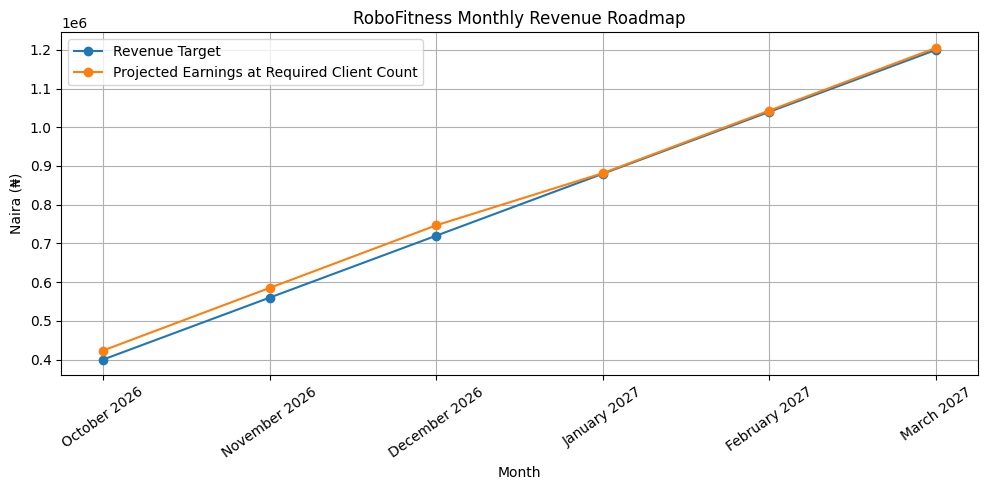


SCHEDULER COMPLETE
Available appointment slots: 65
Active clients: 6
Sessions requested: 18
Sessions booked: 18
Sessions still to allocate: 0
Estimated current monthly earnings: ₦261,700
Excel report created: RoboFitness_Client_Scheduler.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# ============================================================
# ROBOFITNESS FOOTBALL-FIRST CLIENT SCHEDULER
# Updated: October 2026
# ============================================================
#
# WORKING HOURS
# Monday-Friday: 6:30 AM - 9:00 PM
# Saturday:      6:30 AM - 5:00 PM
# Sunday:        OFF
#
# FOOTBALL TRAINING
# Monday-Friday: 4:00 PM - 6:00 PM
#
# SESSION LENGTH: 1 hour
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from collections import defaultdict
from google.colab import files

# ============================================================
# 1. BUSINESS SETTINGS
# ============================================================

BASE_SALARY = 100_000
PLAN_PRICE = 77_000
COMMISSION_RATE = 0.35

COMMISSION_PER_CLIENT = PLAN_PRICE * COMMISSION_RATE

SESSION_LENGTH_MINUTES = 60
MAX_CLIENTS_PER_SHARED_SESSION = 2

CANCELLATION_RATE = 0.25

print("=" * 60)
print("ROBOFITNESS CLIENT MANAGEMENT SYSTEM")
print("=" * 60)

print(f"Base salary: ₦{BASE_SALARY:,.0f}")
print(f"Plan price: ₦{PLAN_PRICE:,.0f}")
print(f"Commission rate: {COMMISSION_RATE:.0%}")
print(f"Commission per eligible client: ₦{COMMISSION_PER_CLIENT:,.0f}")


# ============================================================
# 2. WORKING HOURS AND FOOTBALL PROTECTION
# ============================================================

WORKING_HOURS = {
    "Monday": ("06:30", "21:00"),
    "Tuesday": ("06:30", "21:00"),
    "Wednesday": ("06:30", "21:00"),
    "Thursday": ("06:30", "21:00"),
    "Friday": ("06:30", "21:00"),
    "Saturday": ("06:30", "17:00"),
    "Sunday": None
}

FOOTBALL_DAYS = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

FOOTBALL_START = "16:00"
FOOTBALL_END = "18:00"

DAYS = list(WORKING_HOURS.keys())

print("\nWEEKLY AVAILABILITY")

for day, hours in WORKING_HOURS.items():
    if hours is None:
        print(f"{day}: OFF")
    elif day in FOOTBALL_DAYS:
        print(
            f"{day}: {hours[0]}-{hours[1]} "
            f"| Football: {FOOTBALL_START}-{FOOTBALL_END}"
        )
    else:
        print(f"{day}: {hours[0]}-{hours[1]}")


# ============================================================
# 3. GENERATE AVAILABLE ONE-HOUR SLOTS
# ============================================================

def time_to_minutes(time_string):
    """Convert HH:MM into minutes after midnight."""
    hours, minutes = map(int, time_string.split(":"))
    return hours * 60 + minutes


def minutes_to_time(minutes):
    """Convert minutes after midnight into HH:MM."""
    hours = minutes // 60
    mins = minutes % 60
    return f"{hours:02d}:{mins:02d}"


def overlaps(start1, end1, start2, end2):
    """Return True when two time intervals overlap."""
    return start1 < end2 and start2 < end1


def generate_slots():
    """
    Generate one-hour appointments.

    No appointments are created on Sunday.
    No weekday appointment can overlap football training.
    """

    slots = []

    for day, hours in WORKING_HOURS.items():

        if hours is None:
            continue

        work_start = time_to_minutes(hours[0])
        work_end = time_to_minutes(hours[1])

        start = work_start

        while start + SESSION_LENGTH_MINUTES <= work_end:

            end = start + SESSION_LENGTH_MINUTES

            # Protect weekday football training.
            football_conflict = False

            if day in FOOTBALL_DAYS:
                football_start = time_to_minutes(FOOTBALL_START)
                football_end = time_to_minutes(FOOTBALL_END)

                football_conflict = overlaps(
                    start,
                    end,
                    football_start,
                    football_end
                )

            if not football_conflict:
                slots.append({
                    "Day": day,
                    "Start": minutes_to_time(start),
                    "End": minutes_to_time(end),
                    "Start_Minutes": start,
                    "End_Minutes": end
                })

            start += SESSION_LENGTH_MINUTES

    return pd.DataFrame(slots)


slots_df = generate_slots()

print("\nAVAILABLE CLIENT APPOINTMENTS")

daily_capacity = (
    slots_df.groupby("Day")
    .size()
    .reindex(DAYS, fill_value=0)
    .rename("Available One-Hour Slots")
    .reset_index()
    .rename(columns={"index": "Day"})
)

display(daily_capacity)

print(
    f"\nTheoretical weekly capacity: "
    f"{len(slots_df)} one-hour appointments"
)


# ============================================================
# 4. CLIENT DATABASE
# ============================================================
#
# Update this table whenever clients join, pause, cancel,
# change goals, or agree to shared training.
#
# Status:
# Active = currently training
# Paused = temporarily inactive
# Potential = not yet confirmed
#
# Share_OK must be True only when the client has agreed
# to shared sessions.
#
# ============================================================

clients = pd.DataFrame([
    {
        "Client": "Ibrahim",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Saturday"],
        "Paying": True
    },
    {
        "Client": "Lucy",
        "Status": "Active",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Friday"],
        "Paying": True
    },
    {
        "Client": "Isabel",
        "Status": "Active",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Friday"],
        "Paying": True
    },
    {
        "Client": "Mohammed",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Wednesday", "Thursday"],
        "Paying": True
    },
    {
        "Client": "Albert",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": True,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Saturday"],
        "Paying": True
    },
    {
        "Client": "Albert's Wife",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": True,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Saturday"],
        "Paying": True
    },
    {
        "Client": "Noah",
        "Status": "Paused",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Monday", "Wednesday", "Friday"],
        "Paying": False
    },
    {
        "Client": "Alex",
        "Status": "Paused",
        "Goal": "General fitness",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Monday", "Wednesday", "Saturday"],
        "Paying": False
    },
    {
        "Client": "Rita",
        "Status": "Potential",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Monday", "Tuesday", "Thursday"],
        "Paying": False
    }
])

print("\nCLIENT DATABASE")
display(clients)


# ============================================================
# 5. VALIDATE CLIENT INFORMATION
# ============================================================

valid_statuses = {"Active", "Paused", "Potential"}

assert clients["Client"].is_unique, (
    "Each client must have a unique name."
)

assert clients["Status"].isin(valid_statuses).all(), (
    "A client has an invalid status."
)

assert clients["Sessions_Per_Week"].between(1, 4).all(), (
    "Each client must request between 1 and 4 sessions per week."
)

assert clients["Share_OK"].isin([True, False]).all()

assert clients["Paying"].isin([True, False]).all()

print("Client database validation passed.")


# ============================================================
# 6. SCHEDULING ENGINE
# ============================================================
#
# Scheduling rules:
# 1. Only Active clients are scheduled.
# 2. Each appointment lasts one hour.
# 3. A client cannot be booked twice at the same time.
# 4. A client receives no more than one session per day.
# 5. Each client can receive up to four sessions per week.
# 6. Shared training requires both clients' consent.
# 7. Shared clients must have matching stated goals.
# 8. A shared appointment can contain no more than two clients.
# 9. Preferred days are considered first.
# 10. Unscheduled sessions are reported.
#
# This is a practical greedy scheduler, not an optimizer.
# ============================================================

active_clients = clients[
    clients["Status"] == "Active"
].copy()

client_lookup = clients.set_index("Client").to_dict("index")

# One row per booked appointment.
appointments = []

# Track the number of sessions allocated to each client.
sessions_booked = defaultdict(int)

# Track which days each client has attended.
days_booked = defaultdict(set)


def client_can_attend(client_name, day):
    """Check weekly target and one-session-per-day rule."""

    client = client_lookup[client_name]

    if sessions_booked[client_name] >= client["Sessions_Per_Week"]:
        return False

    if day in days_booked[client_name]:
        return False

    return True


def compatible_for_sharing(client_a, client_b):
    """Check whether two clients may share an appointment."""

    a = client_lookup[client_a]
    b = client_lookup[client_b]

    return (
        a["Share_OK"]
        and b["Share_OK"]
        and a["Goal"] == b["Goal"]
    )


def already_booked_together(client_a, client_b):
    """Avoid repeatedly pairing the same clients unnecessarily."""

    for appointment in appointments:
        booked = appointment["Clients"]

        if client_a in booked and client_b in booked:
            return True

    return False


def find_shared_partner(client_name, day):
    """
    Find a consenting, compatible client who:
    - is active,
    - has the same goal,
    - can attend on the same day,
    - has not already been paired with this client.
    """

    for candidate in active_clients["Client"].tolist():

        if candidate == client_name:
            continue

        if not client_can_attend(candidate, day):
            continue

        if not compatible_for_sharing(client_name, candidate):
            continue

        if already_booked_together(client_name, candidate):
            continue

        return candidate

    return None


# Preferred days first; other available days are fallback options.
for client_name in active_clients["Client"].tolist():

    client = client_lookup[client_name]

    preferred_days = client["Preferred_Days"]

    day_order = (
        preferred_days
        + [day for day in DAYS if day not in preferred_days]
    )

    for day in day_order:

        if sessions_booked[client_name] >= client["Sessions_Per_Week"]:
            break

        if not client_can_attend(client_name, day):
            continue

        # Find an available appointment on this day.
        day_slots = slots_df[slots_df["Day"] == day]

        appointment_created = False

        for _, slot in day_slots.iterrows():

            # Determine whether the slot already has an appointment.
            existing_appointment = None

            for appointment in appointments:

                if (
                    appointment["Day"] == day
                    and appointment["Start"] == slot["Start"]
                ):
                    existing_appointment = appointment
                    break

            # Empty slot: book individual training first.
            if existing_appointment is None:

                appointments.append({
                    "Day": day,
                    "Start": slot["Start"],
                    "End": slot["End"],
                    "Clients": [client_name],
                    "Session_Type": "Individual"
                })

                sessions_booked[client_name] += 1
                days_booked[client_name].add(day)

                appointment_created = True
                break

            # Existing shared appointment may accept a second client.
            elif len(existing_appointment["Clients"]) < MAX_CLIENTS_PER_SHARED_SESSION:

                existing_client = existing_appointment["Clients"][0]

                if (
                    client_can_attend(client_name, day)
                    and compatible_for_sharing(
                        client_name,
                        existing_client
                    )
                ):

                    existing_appointment["Clients"].append(client_name)
                    existing_appointment["Session_Type"] = "Shared"

                    sessions_booked[client_name] += 1
                    days_booked[client_name].add(day)

                    appointment_created = True
                    break

        # If no appointment was found, leave the session unallocated.
        # The reporting section below will identify the shortfall.


# ============================================================
# 7. FORMAT THE WEEKLY TIMETABLE
# ============================================================

schedule_rows = []

for appointment in appointments:

    schedule_rows.append({
        "Day": appointment["Day"],
        "Start": appointment["Start"],
        "End": appointment["End"],
        "Client(s)": " + ".join(appointment["Clients"]),
        "Number of Clients": len(appointment["Clients"]),
        "Session Type": appointment["Session_Type"]
    })

schedule_df = pd.DataFrame(schedule_rows)

if not schedule_df.empty:
    schedule_df["Day_Order"] = schedule_df["Day"].map(
        {day: i for i, day in enumerate(DAYS)}
    )

    schedule_df = (
        schedule_df
        .sort_values(["Day_Order", "Start"])
        .drop(columns="Day_Order")
        .reset_index(drop=True)
    )

print("\n" + "=" * 60)
print("WEEKLY CLIENT TIMETABLE")
print("=" * 60)

display(schedule_df)


# ============================================================
# 8. IDENTIFY UNSCHEDULED SESSIONS
# ============================================================

unscheduled_rows = []

for _, client in active_clients.iterrows():

    name = client["Client"]
    target = client["Sessions_Per_Week"]
    booked = sessions_booked[name]
    remaining = max(0, target - booked)

    unscheduled_rows.append({
        "Client": name,
        "Sessions Requested": target,
        "Sessions Booked": booked,
        "Sessions Unscheduled": remaining
    })

unscheduled_df = pd.DataFrame(unscheduled_rows)

print("\nSESSION ALLOCATION REPORT")
display(unscheduled_df)

total_requested = active_clients["Sessions_Per_Week"].sum()
total_booked = sum(sessions_booked.values())
total_unallocated = max(0, total_requested - total_booked)

print(f"Total sessions requested: {total_requested}")
print(f"Total client sessions booked: {total_booked}")
print(f"Total sessions unallocated: {total_unallocated}")


# ============================================================
# 9. CHECK SCHEDULING CONFLICTS
# ============================================================

conflicts = []

for i in range(len(schedule_df)):

    for j in range(i + 1, len(schedule_df)):

        a = schedule_df.iloc[i]
        b = schedule_df.iloc[j]

        if a["Day"] != b["Day"]:
            continue

        a_start = time_to_minutes(a["Start"])
        a_end = time_to_minutes(a["End"])

        b_start = time_to_minutes(b["Start"])
        b_end = time_to_minutes(b["End"])

        if overlaps(a_start, a_end, b_start, b_end):

            conflicts.append({
                "Appointment A": a["Client(s)"],
                "Appointment B": b["Client(s)"],
                "Day": a["Day"]
            })


# Check football protection.
football_conflicts = []

for _, appointment in schedule_df.iterrows():

    if appointment["Day"] not in FOOTBALL_DAYS:
        continue

    start = time_to_minutes(appointment["Start"])
    end = time_to_minutes(appointment["End"])

    if overlaps(
        start,
        end,
        time_to_minutes(FOOTBALL_START),
        time_to_minutes(FOOTBALL_END)
    ):
        football_conflicts.append(appointment.to_dict())


print("\nSCHEDULING VALIDATION")

if conflicts:
    print("WARNING: Appointment conflicts detected.")
    display(pd.DataFrame(conflicts))
else:
    print("PASS: No overlapping appointments.")

if football_conflicts:
    print("WARNING: Football training conflicts detected.")
    display(pd.DataFrame(football_conflicts))
else:
    print("PASS: Football training remains protected.")

if "Sunday" not in schedule_df["Day"].values if not schedule_df.empty else True:
    print("PASS: No Sunday appointments.")


# ============================================================
# 10. REVENUE TARGET ROADMAP
# ============================================================

monthly_targets = pd.DataFrame([
    {"Month": "October 2026", "Target": 400_000},
    {"Month": "November 2026", "Target": 560_000},
    {"Month": "December 2026", "Target": 720_000},
    {"Month": "January 2027", "Target": 880_000},
    {"Month": "February 2027", "Target": 1_040_000},
    {"Month": "March 2027", "Target": 1_200_000}
])


def clients_needed_for_target(target):
    """
    Calculate the minimum number of commission-eligible clients
    required to reach a target, assuming the base salary and
    full commission per client.
    """

    shortfall = max(0, target - BASE_SALARY)

    return int(
        -(-shortfall // COMMISSION_PER_CLIENT)
    )


monthly_targets["Clients Needed"] = monthly_targets["Target"].apply(
    clients_needed_for_target
)

monthly_targets["Projected Earnings"] = (
    BASE_SALARY
    + monthly_targets["Clients Needed"] * COMMISSION_PER_CLIENT
)

monthly_targets["Additional Clients vs Previous Target"] = (
    monthly_targets["Clients Needed"].diff().fillna(
        monthly_targets["Clients Needed"].iloc[0]
    ).astype(int)
)

print("\nMONTHLY REVENUE ROADMAP")

display(
    monthly_targets.style.format({
        "Target": "₦{:,.0f}",
        "Projected Earnings": "₦{:,.0f}"
    })
)


# ============================================================
# 11. CURRENT CLIENT REVENUE ESTIMATE
# ============================================================
#
# This is a simple estimate, not confirmation of actual
# payroll. Confirm which clients generate commission.
# ============================================================

paying_active_clients = clients[
    (clients["Status"] == "Active")
    & (clients["Paying"] == True)
]

paying_client_count = len(paying_active_clients)

estimated_earnings = (
    BASE_SALARY
    + paying_client_count * COMMISSION_PER_CLIENT
)

print("\nCURRENT REVENUE ESTIMATE")
print(f"Active paying clients: {paying_client_count}")
print(f"Estimated monthly earnings: ₦{estimated_earnings:,.0f}")


# ============================================================
# 12. CANCELLATION AND CLIENT RETENTION PLANNING
# ============================================================

retention_plan = pd.DataFrame([
    {
        "Action": "Confirm attendance",
        "Frequency": "Before each session",
        "Purpose": "Reduce missed appointments"
    },
    {
        "Action": "Review client progress",
        "Frequency": "Every 2-4 weeks",
        "Purpose": "Show measurable results"
    },
    {
        "Action": "Contact inactive clients",
        "Frequency": "After a missed session",
        "Purpose": "Identify and resolve attendance issues"
    },
    {
        "Action": "Ask for referrals",
        "Frequency": "When clients report progress",
        "Purpose": "Acquire new clients"
    },
    {
        "Action": "Track plan renewals",
        "Frequency": "Before expiry",
        "Purpose": "Reduce revenue gaps"
    }
])

print("\nCLIENT RETENTION PLAN")
display(retention_plan)

print(
    f"\nPlanning cancellation assumption: "
    f"{CANCELLATION_RATE:.0%}"
)

print(
    "This is a planning assumption, not a measured cancellation rate."
)


# ============================================================
# 13. SHARED TRAINING SAFETY RULES
# ============================================================

sharing_rules = pd.DataFrame([
    {
        "Rule": "Consent",
        "Requirement": "Both clients must agree to train together."
    },
    {
        "Rule": "Compatibility",
        "Requirement": "Goals, experience and exercise needs must be compatible."
    },
    {
        "Rule": "Assessment",
        "Requirement": "Screen each client for relevant limitations and risks."
    },
    {
        "Rule": "Coaching",
        "Requirement": "Maintain appropriate supervision and technique."
    },
    {
        "Rule": "Capacity",
        "Requirement": "Maximum two clients per shared appointment."
    }
])

print("\nSHARED TRAINING POLICY")
display(sharing_rules)


# ============================================================
# 14. VISUALIZE REVENUE TARGETS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_targets["Month"],
    monthly_targets["Target"],
    marker="o",
    label="Revenue Target"
)

plt.plot(
    monthly_targets["Month"],
    monthly_targets["Projected Earnings"],
    marker="o",
    label="Projected Earnings at Required Client Count"
)

plt.title("RoboFitness Monthly Revenue Roadmap")
plt.xlabel("Month")
plt.ylabel("Naira (₦)")
plt.xticks(rotation=35)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 15. EXPORT REPORTS TO EXCEL
# ============================================================

output_file = "RoboFitness_Client_Scheduler.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    clients.to_excel(
        writer,
        sheet_name="Client Database",
        index=False
    )

    slots_df.to_excel(
        writer,
        sheet_name="Available Slots",
        index=False
    )

    schedule_df.to_excel(
        writer,
        sheet_name="Weekly Timetable",
        index=False
    )

    unscheduled_df.to_excel(
        writer,
        sheet_name="Session Allocation",
        index=False
    )

    daily_capacity.to_excel(
        writer,
        sheet_name="Daily Capacity",
        index=False
    )

    monthly_targets.to_excel(
        writer,
        sheet_name="Revenue Roadmap",
        index=False
    )

    retention_plan.to_excel(
        writer,
        sheet_name="Retention Plan",
        index=False
    )

    sharing_rules.to_excel(
        writer,
        sheet_name="Sharing Policy",
        index=False
    )


print("\n" + "=" * 60)
print("SCHEDULER COMPLETE")
print("=" * 60)

print(f"Available appointment slots: {len(slots_df)}")
print(f"Active clients: {len(active_clients)}")
print(f"Sessions requested: {total_requested}")
print(f"Sessions booked: {total_booked}")
print(f"Sessions still to allocate: {total_unallocated}")
print(f"Estimated current monthly earnings: ₦{estimated_earnings:,.0f}")
print(f"Excel report created: {output_file}")

files.download(output_file)

ROBOFITNESS CLIENT SCHEDULING AND REVENUE SYSTEM
Base salary: ₦100,000
Commission per eligible client: ₦26,950
Target sessions per client per week: 3
Maximum sessions per client per week: 4

WEEKLY APPOINTMENT CAPACITY


,Day,Available Appointments
0,Monday,12
1,Tuesday,12
2,Wednesday,12
3,Thursday,12
4,Friday,12
5,Saturday,10



Total weekly appointment slots: 70
Sunday: OFF
Football: Protected Monday-Friday, 16:00-18:00

CLIENT DATABASE


,Client,Status,Goal,Share_OK,Sessions_Per_Week,Preferred_Days,Paying
0,Ibrahim,Active,General fitness,False,3,"[Tuesday, Thursday, Saturday]",True
1,Lucy,Active,Weight loss,False,3,"[Tuesday, Thursday, Friday]",True
2,Isabel,Active,Weight loss,False,3,"[Tuesday, Thursday, Friday]",True
3,Mohammed,Active,General fitness,False,3,"[Tuesday, Wednesday, Thursday]",True
4,Mr Albert,Active,General fitness,True,3,"[Tuesday, Thursday, Saturday]",True
5,Albert's Wife,Active,General fitness,True,3,"[Tuesday, Thursday, Saturday]",True
6,Noah,Paused,Weight loss,False,3,"[Monday, Wednesday, Friday]",False
7,Mr Alex,Paused,General fitness,False,3,"[Monday, Wednesday, Saturday]",False
8,Rita,Potential,Weight loss,False,3,"[Monday, Tuesday, Thursday]",False


Client data validation passed.

OPTIMIZATION STATUS: OPTIMAL

OPTIMIZED WEEKLY TIMETABLE


...


MONTHLY GROWTH FEASIBILITY


,Month,Target Clients,Weekly Client Attendances,Shared Attendance (%),Estimated Slots Needed,Theoretical Capacity Feasible
0,October 2026,12,36,0,36.0,True
1,October 2026,12,36,25,31.5,True
2,October 2026,12,36,50,27.0,True
3,October 2026,12,36,75,22.5,True
4,October 2026,12,36,100,18.0,True
5,November 2026,18,54,0,54.0,True
6,November 2026,18,54,25,47.2,True
7,November 2026,18,54,50,40.5,True
8,November 2026,18,54,75,33.8,True
9,November 2026,18,54,100,27.0,True



CURRENT REVENUE ESTIMATE
Active paying clients in the entered database: 6
Estimated monthly earnings: ₦261,700
Note: Confirm each client's actual commission eligibility and payment status before using this estimate.

CLIENT RETENTION ACTION PLAN


,Action,When,Goal
0,Confirm attendance,Before every session,Reduce missed appointments
1,Review progress,Every 2-4 weeks,Keep clients engaged
2,Contact inactive clients,After a missed session,Understand attendance problems
3,Ask for referrals,When clients report progress,Acquire new clients
4,Track renewals,Before each plan expires,Reduce revenue gaps
5,Track cancellations,Monthly,Replace lost clients early



Planning cancellation assumption: 25%
This is an assumption, not a measured cancellation rate. Replace it with your actual monthly data.


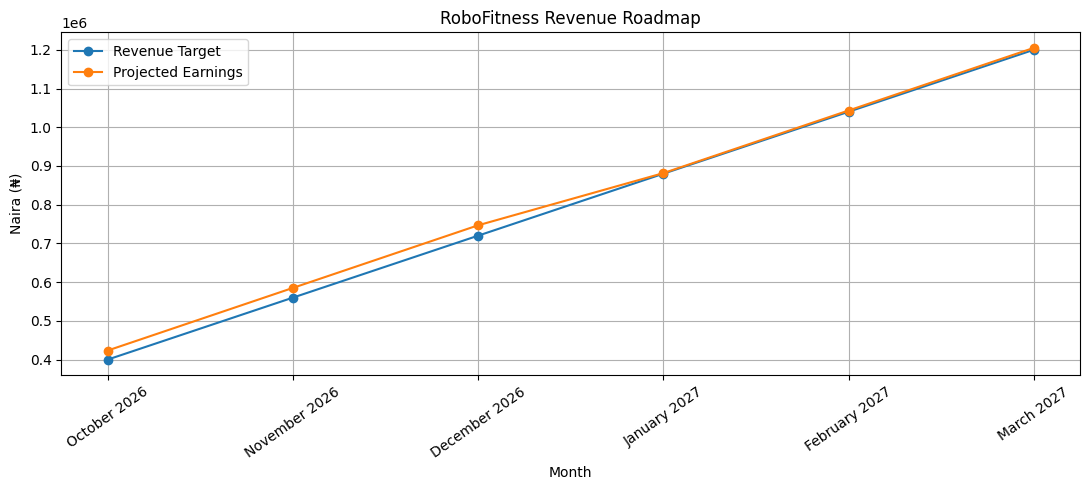


SCHEDULER COMPLETE
Available weekly appointment slots: 70
Clients included in schedule: 7
Sessions requested: 21
Sessions booked: 21
Sessions unallocated: 0
Excel report: RoboFitness_Growth_Scheduler.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
# ============================================================
# ROBOFITNESS: FOOTBALL-FIRST BUSINESS SCHEDULER
# Planning period: October 2026 - March 2027
# ============================================================
#
# WORKING HOURS
# Monday-Friday: 06:30-16:00 and 18:00-21:00
# Saturday:      06:30-17:00
# Sunday:        OFF
#
# FOOTBALL: Monday-Friday, 16:00-18:00
#
# Each client:
#   - Target: 3 one-hour sessions per week
#   - Maximum: 4 sessions per week
#   - May share only with consent and compatible goals
#
# ============================================================

import sys
import subprocess
import importlib.util

# Install the optimization library in Google Colab if needed.
if importlib.util.find_spec("ortools") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ortools"
    ])

import pandas as pd
import matplotlib.pyplot as plt

from ortools.sat.python import cp_model
from IPython.display import display
from google.colab import files


# ============================================================
# 1. BUSINESS SETTINGS
# ============================================================

BASE_SALARY = 100_000
PLAN_PRICE = 77_000
COMMISSION_RATE = 0.35

COMMISSION_PER_CLIENT = PLAN_PRICE * COMMISSION_RATE

TARGET_SESSIONS = 3
MAX_SESSIONS = 4

MAX_CLIENTS_PER_SHARED_SESSION = 2

# Used for planning only until you calculate your actual rate.
ASSUMED_MONTHLY_CANCELLATION_RATE = 0.25

print("=" * 65)
print("ROBOFITNESS CLIENT SCHEDULING AND REVENUE SYSTEM")
print("=" * 65)

print(f"Base salary: ₦{BASE_SALARY:,.0f}")
print(f"Commission per eligible client: ₦{COMMISSION_PER_CLIENT:,.0f}")
print(f"Target sessions per client per week: {TARGET_SESSIONS}")
print(f"Maximum sessions per client per week: {MAX_SESSIONS}")


# ============================================================
# 2. WORKING HOURS
# ============================================================

DAYS = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday"
]

WORKING_HOURS = {
    "Monday": ("06:30", "16:00"),
    "Tuesday": ("06:30", "16:00"),
    "Wednesday": ("06:30", "16:00"),
    "Thursday": ("06:30", "16:00"),
    "Friday": ("06:30", "16:00"),
    "Saturday": ("06:30", "17:00"),
    "Sunday": None
}

EVENING_HOURS = {
    "Monday": ("18:00", "21:00"),
    "Tuesday": ("18:00", "21:00"),
    "Wednesday": ("18:00", "21:00"),
    "Thursday": ("18:00", "21:00"),
    "Friday": ("18:00", "21:00")
}

FOOTBALL_START = "16:00"
FOOTBALL_END = "18:00"

SESSION_LENGTH_MINUTES = 60

# Slots are aligned to a 06:30 start in the daytime.
# This avoids overlapping appointments.
# Last daytime appointment on weekdays: 14:30-15:30.
# Evening appointments: 18:00-19:00, 19:00-20:00,
#                       20:00-21:00.
# Saturday's final appointment: 15:30-16:30.


# ============================================================
# 3. TIME UTILITIES
# ============================================================

def time_to_minutes(time_string):
    hours, minutes = map(int, time_string.split(":"))
    return hours * 60 + minutes


def minutes_to_time(minutes):
    hours = minutes // 60
    mins = minutes % 60
    return f"{hours:02d}:{mins:02d}"


def overlaps(start_a, end_a, start_b, end_b):
    return start_a < end_b and start_b < end_a


# ============================================================
# 4. GENERATE AVAILABLE APPOINTMENTS
# ============================================================

def generate_slots():
    slots = []

    for day in DAYS:

        periods = [WORKING_HOURS[day]]

        if day in EVENING_HOURS:
            periods.append(EVENING_HOURS[day])

        for period in periods:

            work_start = time_to_minutes(period[0])
            work_end = time_to_minutes(period[1])

            start = work_start

            while start + SESSION_LENGTH_MINUTES <= work_end:

                end = start + SESSION_LENGTH_MINUTES

                # Explicitly reject any appointment that overlaps
                # football training.
                football_conflict = (
                    day in DAYS[:5]
                    and overlaps(
                        start,
                        end,
                        time_to_minutes(FOOTBALL_START),
                        time_to_minutes(FOOTBALL_END)
                    )
                )

                if not football_conflict:
                    slots.append({
                        "Day": day,
                        "Start": minutes_to_time(start),
                        "End": minutes_to_time(end),
                        "Start_Minutes": start,
                        "End_Minutes": end
                    })

                start += SESSION_LENGTH_MINUTES

    return pd.DataFrame(slots)


slots_df = generate_slots()

daily_capacity = (
    slots_df.groupby("Day")
    .size()
    .reindex(DAYS, fill_value=0)
    .rename("Available Appointments")
    .reset_index()
)

print("\nWEEKLY APPOINTMENT CAPACITY")
display(daily_capacity)

TOTAL_WEEKLY_SLOTS = len(slots_df)

print(f"\nTotal weekly appointment slots: {TOTAL_WEEKLY_SLOTS}")
print("Sunday: OFF")
print("Football: Protected Monday-Friday, 16:00-18:00")


# ============================================================
# 5. CLIENT DATABASE
# ============================================================
#
# Important:
# - Update statuses as circumstances change.
# - "Potential" clients are scheduled provisionally.
# - "Paying" controls revenue estimates, not attendance.
# - Share_OK must reflect actual client consent.
#
# The records below are starting assumptions based on your
# timetable. Confirm them before relying on the results.
# ============================================================

clients = pd.DataFrame([
    {
        "Client": "Ibrahim",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Saturday"],
        "Paying": True
    },
    {
        "Client": "Lucy",
        "Status": "Active",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Friday"],
        "Paying": True
    },
    {
        "Client": "Isabel",
        "Status": "Active",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Friday"],
        "Paying": True
    },
    {
        "Client": "Mohammed",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Wednesday", "Thursday"],
        "Paying": True
    },
    {
        "Client": "Mr Albert",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": True,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Saturday"],
        "Paying": True
    },
    {
        "Client": "Albert's Wife",
        "Status": "Active",
        "Goal": "General fitness",
        "Share_OK": True,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Tuesday", "Thursday", "Saturday"],
        "Paying": True
    },
    {
        "Client": "Noah",
        "Status": "Paused",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Monday", "Wednesday", "Friday"],
        "Paying": False
    },
    {
        "Client": "Mr Alex",
        "Status": "Paused",
        "Goal": "General fitness",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Monday", "Wednesday", "Saturday"],
        "Paying": False
    },
    {
        "Client": "Rita",
        "Status": "Potential",
        "Goal": "Weight loss",
        "Share_OK": False,
        "Sessions_Per_Week": 3,
        "Preferred_Days": ["Monday", "Tuesday", "Thursday"],
        "Paying": False
    }
])

print("\nCLIENT DATABASE")
display(clients)


# ============================================================
# 6. VALIDATE CLIENT DATA
# ============================================================

assert clients["Client"].is_unique, (
    "Each client must have a unique name."
)

assert clients["Sessions_Per_Week"].between(
    1, MAX_SESSIONS
).all(), "Invalid weekly session target."

assert clients["Share_OK"].isin([True, False]).all()

valid_statuses = {"Active", "Paused", "Potential"}

assert clients["Status"].isin(valid_statuses).all()

print("Client data validation passed.")


# ============================================================
# 7. OPTIMIZATION SCHEDULER
# ============================================================
#
# The solver:
# - Maximizes the number of scheduled sessions.
# - Favors each client's preferred days.
# - Prevents double-booking.
# - Limits each client to one session per day.
# - Keeps football protected.
# - Allows sharing only between compatible, consenting clients.
# - Reports sessions that cannot be allocated.
#
# Each client has a target of three sessions per week.
# ============================================================

def build_schedule(client_table):

    eligible = client_table[
        client_table["Status"].isin(["Active", "Potential"])
    ].copy()

    eligible_names = eligible["Client"].tolist()

    client_info = eligible.set_index("Client").to_dict("index")

    model = cp_model.CpModel()

    # x[(client, slot_index)] = 1 if the client is assigned there.
    x = {}

    # Missing-session variables allow the solver to return the
    # best feasible schedule even if the full demand will not fit.
    unmet = {}

    for name in eligible_names:

        info = client_info[name]

        preferred_days = info["Preferred_Days"]

        for slot_index, slot in slots_df.iterrows():

            # Every eligible client may be assigned to an available
            # slot. Preferred days are rewarded in the objective.
            x[(name, slot_index)] = model.NewBoolVar(
                f"x_{eligible_names.index(name)}_{slot_index}"
            )

        unmet[name] = model.NewIntVar(
            0,
            info["Sessions_Per_Week"],
            f"unmet_{eligible_names.index(name)}"
        )

        client_vars = [
            x[(name, i)] for i in range(len(slots_df))
        ]

        # Schedule the requested number of sessions where possible.
        model.Add(
            sum(client_vars) + unmet[name]
            == info["Sessions_Per_Week"]
        )

        # No more than one appointment per client per day.
        for day in DAYS:

            day_vars = [
                x[(name, i)]
                for i, slot in slots_df.iterrows()
                if slot["Day"] == day
            ]

            if day_vars:
                model.Add(sum(day_vars) <= 1)

        # Maximum weekly frequency.
        model.Add(sum(client_vars) <= MAX_SESSIONS)

    # Each appointment has capacity for at most two clients.
    for slot_index in range(len(slots_df)):

        model.Add(
            sum(
                x[(name, slot_index)]
                for name in eligible_names
            ) <= MAX_CLIENTS_PER_SHARED_SESSION
        )

    # Clients who do not both consent to sharing, or whose goals
    # differ, cannot occupy the same appointment.
    for slot_index in range(len(slots_df)):

        for i, name_a in enumerate(eligible_names):

            for name_b in eligible_names[i + 1:]:

                a = client_info[name_a]
                b = client_info[name_b]

                compatible = (
                    a["Share_OK"]
                    and b["Share_OK"]
                    and a["Goal"] == b["Goal"]
                )

                if not compatible:
                    model.Add(
                        x[(name_a, slot_index)]
                        + x[(name_b, slot_index)]
                        <= 1
                    )

    # Objective:
    # First, avoid unallocated sessions.
    # Second, prefer each client's selected days.
    # Third, prefer the earlier preferred-day assignments.
    objective_terms = []

    for name in eligible_names:

        objective_terms.append(-10000 * unmet[name])

        preferred_days = client_info[name]["Preferred_Days"]

        for slot_index, slot in slots_df.iterrows():

            if slot["Day"] in preferred_days:
                objective_terms.append(
                    100 * x[(name, slot_index)]
                )

            else:
                objective_terms.append(
                    1 * x[(name, slot_index)]
                )

    model.Maximize(sum(objective_terms))

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = 20
    solver.parameters.num_search_workers = 8

    status = solver.Solve(model)

    if status not in (
        cp_model.OPTIMAL,
        cp_model.FEASIBLE
    ):
        raise RuntimeError(
            "The solver could not produce a feasible schedule."
        )

    schedule_rows = []
    allocation_rows = []

    for slot_index, slot in slots_df.iterrows():

        assigned = [
            name
            for name in eligible_names
            if solver.Value(x[(name, slot_index)]) == 1
        ]

        if assigned:

            is_shared = len(assigned) == 2

            schedule_rows.append({
                "Day": slot["Day"],
                "Start": slot["Start"],
                "End": slot["End"],
                "Client(s)": " + ".join(assigned),
                "Number of Clients": len(assigned),
                "Session Type": (
                    "Shared" if is_shared else "Individual"
                ),
                "Provisional": any(
                    client_info[name]["Status"] == "Potential"
                    for name in assigned
                )
            })

    for name in eligible_names:

        info = client_info[name]

        booked = sum(
            solver.Value(x[(name, i)])
            for i in range(len(slots_df))
        )

        allocation_rows.append({
            "Client": name,
            "Status": info["Status"],
            "Sessions Requested": info["Sessions_Per_Week"],
            "Sessions Booked": booked,
            "Sessions Unallocated": solver.Value(unmet[name])
        })

    schedule = pd.DataFrame(schedule_rows)
    allocation = pd.DataFrame(allocation_rows)

    if not schedule.empty:
        day_order = {day: i for i, day in enumerate(DAYS)}

        schedule["Day_Order"] = schedule["Day"].map(day_order)

        schedule = (
            schedule.sort_values(["Day_Order", "Start"])
            .drop(columns="Day_Order")
            .reset_index(drop=True)
        )

    return schedule, allocation, solver.StatusName(status)


schedule_df, allocation_df, solver_status = build_schedule(clients)

print("\nOPTIMIZATION STATUS:", solver_status)

print("\nOPTIMIZED WEEKLY TIMETABLE")
display(schedule_df)

print("\nCLIENT SESSION ALLOCATION")
display(allocation_df)


# ============================================================
# 8. CHECK FOOTBALL AND APPOINTMENT CONFLICTS
# ============================================================

football_conflicts = []

for _, row in schedule_df.iterrows():

    if row["Day"] not in DAYS[:5]:
        continue

    start = time_to_minutes(row["Start"])
    end = time_to_minutes(row["End"])

    if overlaps(
        start,
        end,
        time_to_minutes(FOOTBALL_START),
        time_to_minutes(FOOTBALL_END)
    ):
        football_conflicts.append(row.to_dict())

if football_conflicts:
    print("ERROR: Football training conflict detected.")
    display(pd.DataFrame(football_conflicts))
else:
    print("\nPASS: No client appointments overlap football.")

if not schedule_df.empty:

    assert "Sunday" not in schedule_df["Day"].values

    print("PASS: Sunday remains off.")


# ============================================================
# 9. REVENUE ROADMAP: OCTOBER 2026 - MARCH 2027
# ============================================================

monthly_targets = pd.DataFrame([
    {"Month": "October 2026", "Revenue_Target": 400_000},
    {"Month": "November 2026", "Revenue_Target": 560_000},
    {"Month": "December 2026", "Revenue_Target": 720_000},
    {"Month": "January 2027", "Revenue_Target": 880_000},
    {"Month": "February 2027", "Revenue_Target": 1_040_000},
    {"Month": "March 2027", "Revenue_Target": 1_200_000}
])


def clients_needed_for_target(target):
    shortfall = max(0, target - BASE_SALARY)

    return int(
        -(-shortfall // COMMISSION_PER_CLIENT)
    )


monthly_targets["Clients_Needed"] = (
    monthly_targets["Revenue_Target"]
    .apply(clients_needed_for_target)
)

monthly_targets["Projected_Earnings"] = (
    BASE_SALARY
    + monthly_targets["Clients_Needed"] * COMMISSION_PER_CLIENT
)

monthly_targets["New_Clients_vs_Previous_Target"] = (
    monthly_targets["Clients_Needed"]
    .diff()
    .fillna(monthly_targets["Clients_Needed"].iloc[0])
    .astype(int)
)

print("\nMONTHLY REVENUE TARGETS")

display(
    monthly_targets.style.format({
        "Revenue_Target": "₦{:,.0f}",
        "Projected_Earnings": "₦{:,.0f}"
    })
)


# ============================================================
# 10. CAPACITY TEST AS CLIENTS GROW
# ============================================================
#
# All clients are assumed to require three sessions per week.
#
# Share percentage means the fraction of all client session
# attendances that occur in shared appointments.
#
# Example:
# 50% shared attendance means half of all attendances happen
# in pairs; the other half happen individually.
#
# This is a theoretical capacity test. Actual compatibility,
# consent, preferred days, and availability may reduce capacity.
# ============================================================

capacity_scenarios = []

for share_percentage in [0, 25, 50, 75, 100]:

    # If p of all client attendances are paired, each pair
    # saves one appointment slot for every two shared attendances.
    slot_factor = 1 - (share_percentage / 100) / 2

    theoretical_clients = int(
        TOTAL_WEEKLY_SLOTS
        // (TARGET_SESSIONS * slot_factor)
    )

    capacity_scenarios.append({
        "Shared Attendance (%)": share_percentage,
        "Weekly Slots Needed per Client": round(
            TARGET_SESSIONS * slot_factor, 2
        ),
        "Theoretical Weekly Client Capacity": theoretical_clients
    })

capacity_df = pd.DataFrame(capacity_scenarios)

print("\nCAPACITY UNDER DIFFERENT SHARING SCENARIOS")
display(capacity_df)


# Test every monthly client target against weekly slot capacity.
growth_capacity_rows = []

for _, row in monthly_targets.iterrows():

    client_count = int(row["Clients_Needed"])
    required_attendances = client_count * TARGET_SESSIONS

    for share_percentage in [0, 25, 50, 75, 100]:

        slot_factor = 1 - (share_percentage / 100) / 2

        estimated_slots_needed = (
            required_attendances * slot_factor
        )

        fits = estimated_slots_needed <= TOTAL_WEEKLY_SLOTS

        growth_capacity_rows.append({
            "Month": row["Month"],
            "Target Clients": client_count,
            "Weekly Client Attendances": required_attendances,
            "Shared Attendance (%)": share_percentage,
            "Estimated Slots Needed": round(estimated_slots_needed, 1),
            "Theoretical Capacity Feasible": fits
        })

growth_capacity_df = pd.DataFrame(growth_capacity_rows)

print("\nMONTHLY GROWTH FEASIBILITY")
display(growth_capacity_df)


# ============================================================
# 11. ESTIMATE CURRENT EARNINGS
# ============================================================

active_paying = clients[
    (clients["Status"] == "Active")
    & (clients["Paying"] == True)
]

current_paying_count = len(active_paying)

estimated_current_earnings = (
    BASE_SALARY
    + current_paying_count * COMMISSION_PER_CLIENT
)

print("\nCURRENT REVENUE ESTIMATE")
print(f"Active paying clients in the entered database: {current_paying_count}")
print(f"Estimated monthly earnings: ₦{estimated_current_earnings:,.0f}")

print(
    "Note: Confirm each client's actual commission eligibility "
    "and payment status before using this estimate."
)


# ============================================================
# 12. CANCELLATION AND RETENTION PLANNING
# ============================================================

retention_actions = pd.DataFrame([
    {
        "Action": "Confirm attendance",
        "When": "Before every session",
        "Goal": "Reduce missed appointments"
    },
    {
        "Action": "Review progress",
        "When": "Every 2-4 weeks",
        "Goal": "Keep clients engaged"
    },
    {
        "Action": "Contact inactive clients",
        "When": "After a missed session",
        "Goal": "Understand attendance problems"
    },
    {
        "Action": "Ask for referrals",
        "When": "When clients report progress",
        "Goal": "Acquire new clients"
    },
    {
        "Action": "Track renewals",
        "When": "Before each plan expires",
        "Goal": "Reduce revenue gaps"
    },
    {
        "Action": "Track cancellations",
        "When": "Monthly",
        "Goal": "Replace lost clients early"
    }
])

print("\nCLIENT RETENTION ACTION PLAN")
display(retention_actions)

print(
    "\nPlanning cancellation assumption:",
    f"{ASSUMED_MONTHLY_CANCELLATION_RATE:.0%}"
)

print(
    "This is an assumption, not a measured cancellation rate. "
    "Replace it with your actual monthly data."
)


# ============================================================
# 13. REVENUE VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_targets["Month"],
    monthly_targets["Revenue_Target"],
    marker="o",
    label="Revenue Target"
)

plt.plot(
    monthly_targets["Month"],
    monthly_targets["Projected_Earnings"],
    marker="o",
    label="Projected Earnings"
)

plt.title("RoboFitness Revenue Roadmap")
plt.xlabel("Month")
plt.ylabel("Naira (₦)")
plt.xticks(rotation=35)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 14. EXPORT ALL REPORTS TO EXCEL
# ============================================================

output_file = "RoboFitness_Growth_Scheduler.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    clients.to_excel(
        writer,
        sheet_name="Client Database",
        index=False
    )

    slots_df.to_excel(
        writer,
        sheet_name="Available Slots",
        index=False
    )

    schedule_df.to_excel(
        writer,
        sheet_name="Weekly Timetable",
        index=False
    )

    allocation_df.to_excel(
        writer,
        sheet_name="Session Allocation",
        index=False
    )

    daily_capacity.to_excel(
        writer,
        sheet_name="Daily Capacity",
        index=False
    )

    monthly_targets.to_excel(
        writer,
        sheet_name="Revenue Roadmap",
        index=False
    )

    capacity_df.to_excel(
        writer,
        sheet_name="Sharing Scenarios",
        index=False
    )

    growth_capacity_df.to_excel(
        writer,
        sheet_name="Growth Feasibility",
        index=False
    )

    retention_actions.to_excel(
        writer,
        sheet_name="Retention Plan",
        index=False
    )

print("\n" + "=" * 65)
print("SCHEDULER COMPLETE")
print("=" * 65)

print(f"Available weekly appointment slots: {TOTAL_WEEKLY_SLOTS}")
print(f"Clients included in schedule: {len(allocation_df)}")
print(
    "Sessions requested:",
    int(allocation_df["Sessions Requested"].sum())
)
print(
    "Sessions booked:",
    int(allocation_df["Sessions Booked"].sum())
)
print(
    "Sessions unallocated:",
    int(allocation_df["Sessions Unallocated"].sum())
)

print(f"Excel report: {output_file}")

files.download(output_file)